# Analisis Value at Risk dengan EVT Block Maxima (R)
## Saham TLKM, ISAT, dan EXCL | 2019–2025

## 1. Persiapan
### 1.1. Pustaka dan Pengaturan Grafik

Pustaka R digunakan untuk mengambil data, membuat grafik, menghitung return, dan mengestimasi VaR.

In [1]:
suppressPackageStartupMessages({
    library(quantmod)
    library(evd)
    library(extRemes)
    library(moments)
    library(ggplot2)
    library(dplyr)
    library(tidyr)
})

options(repr.plot.width = 12, repr.plot.height = 5, digits = 5)
theme_set(theme_minimal(base_size = 15) + theme(text = element_text(face = "bold")))

long_series <- function(x) {
    data <- data.frame(Tanggal = as.Date(index(x)), coredata(x), check.names = FALSE)
    data <- pivot_longer(data, -Tanggal, names_to = "Saham", values_to = "Nilai")
    mutate(data, Saham = factor(Saham, levels = SAHAM))
}

percent <- function(x) paste0(formatC(100 * x, format = "f", digits = 1), "%")

Warning message:
"package 'evd' was built under R version 4.5.3"


Warning message:
"package 'extRemes' was built under R version 4.5.3"


Warning message:
"package 'Lmoments' was built under R version 4.5.3"


Warning message:
"package 'distillery' was built under R version 4.5.2"


### 1.2. Pengaturan Analisis

Analisis menggunakan blok lima hari perdagangan, tingkat kepercayaan 95% dan 99%, serta contoh investasi Rp1 miliar per saham.

In [2]:
TICKERS <- c(TLKM = "TLKM.JK", ISAT = "ISAT.JK", EXCL = "EXCL.JK")
SAHAM <- names(TICKERS)
START_DATE <- as.Date("2019-01-01")
END_DATE <- as.Date("2026-01-01")
ESTIMASI_AKHIR <- as.Date("2024-12-31")
BACKTESTING_AWAL <- as.Date("2025-01-01")
BACKTESTING_AKHIR <- as.Date("2025-12-31")
BLOCK_SIZE <- 5
CONFIDENCE_LEVELS <- c(0.95, 0.99)
SIGNIFICANCE <- 0.05
INVESTMENT <- 1e9
SEED <- 123
set.seed(SEED)
COLORS <- c(TLKM = "#26799c", ISAT = "#159b80", EXCL = "#c88718")

HAPUS_HARI_NOL <- TRUE
TANGGAL_DIPERTAHANKAN <- as.Date("2023-08-25")

## 2. Pengumpulan dan Pemeriksaan Data
### 2.1. Data Harga Harian

In [3]:
raw_data <- lapply(TICKERS, function(ticker) {
    getSymbols(ticker, src = "yahoo", from = START_DATE, to = END_DATE, auto.assign = FALSE)
})
prices <- do.call(merge, lapply(raw_data, Ad))
volume <- do.call(merge, lapply(raw_data, Vo))
colnames(prices) <- colnames(volume) <- SAHAM

tanggal_manual <- as.Date("2019-06-19")
close_profindo <- 4100
if (tanggal_manual %in% index(prices) && is.na(as.numeric(prices[tanggal_manual, "TLKM"]))) {
    tlkm <- raw_data[["TLKM"]]
    tanggal_acuan <- as.Date("2019-06-18")
    faktor <- as.numeric(Ad(tlkm)[tanggal_acuan]) / as.numeric(Cl(tlkm)[tanggal_acuan])
    prices[tanggal_manual, "TLKM"] <- close_profindo * faktor
}

prices <- na.omit(prices[index(prices) != as.Date("2019-01-01"), ])
volume <- volume[index(prices)]

tabel_harga <- data.frame(Tanggal = as.Date(index(prices)), coredata(prices))
head(tabel_harga)
tail(tabel_harga)

Warning message:
"TLKM.JK contains missing values. Some functions will not work if objects contain missing values in the middle of the series. Consider using na.omit(), na.approx(), na.fill(), etc to remove or replace them."


,Tanggal,TLKM,ISAT,EXCL
,<date>,<dbl>,<dbl>,<dbl>
1,2019-01-02,2423.7,307.40,1656.6
2,2019-01-03,2430.2,308.33,1690.1
3,2019-01-04,2410.7,322.35,1706.8
4,2019-01-07,2449.7,329.82,1790.5
5,2019-01-08,2469.2,337.29,1832.4
6,2019-01-09,2423.7,420.45,1882.6


,Tanggal,TLKM,ISAT,EXCL
,<date>,<dbl>,<dbl>,<dbl>
1699,2025-12-19,3152.9,2316.2,3900
1700,2025-12-22,3208.4,2325.7,3760
1701,2025-12-23,3208.4,2306.7,3740
1702,2025-12-24,3199.1,2287.6,3750
1703,2025-12-29,3226.9,2325.7,3830
1704,2025-12-30,3217.6,2211.3,3750


## 3. Eksplorasi Data Harga Saham
### 3.1. Statistik Deskriptif Harga

In [4]:
price_summary <- data.frame(
    Saham = SAHAM,
    N = nrow(prices),
    Mean = colMeans(prices),
    Std = apply(prices, 2, sd),
    Minimum = apply(prices, 2, min),
    Q1 = apply(prices, 2, quantile, probs = 0.25),
    Median = apply(prices, 2, median),
    Q3 = apply(prices, 2, quantile, probs = 0.75),
    Maksimum = apply(prices, 2, max),
    row.names = NULL
)
price_summary
harga_tahunan <- mutate(long_series(prices), Tahun = format(Tanggal, "%Y"))
observasi_tahunan <- count(harga_tahunan, Tahun, Saham, name = "Observasi")
pivot_wider(observasi_tahunan, names_from = Saham, values_from = Observasi)

Saham,N,Mean,Std,Minimum,Q1,Median,Q3,Maksimum
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TLKM,1704,2728.7,412.82,1774.76,2417.02,2697.9,3086.2,3681.8
ISAT,1704,1351.9,690.62,224.24,609.19,1304.2,2001.6,2733.9
EXCL,1704,2197.1,352.46,1179.73,1978.60,2119.4,2392.9,3900.0


Tahun,TLKM,ISAT,EXCL
<chr>,<int>,<int>,<int>
2019,257,257,257
2020,242,242,242
2021,247,247,247
2022,246,246,246
2023,239,239,239
2024,237,237,237
2025,236,236,236


### 3.2. Pergerakan Harga Saham

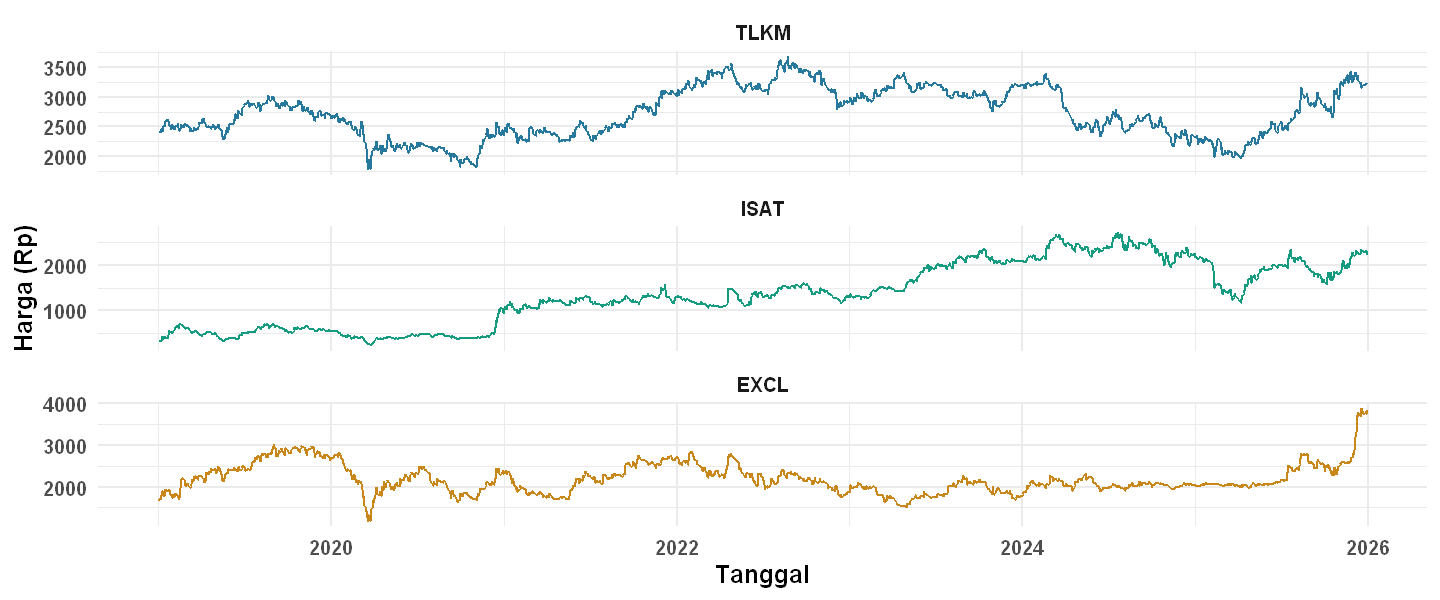

In [5]:
ggplot(long_series(prices), aes(Tanggal, Nilai, color = Saham)) +
    geom_line(linewidth = 0.7) +
    facet_wrap(~Saham, ncol = 1, scales = "free_y") +
    scale_color_manual(values = COLORS) +
    labs(x = "Tanggal", y = "Harga (Rp)") +
    theme(legend.position = "none")

### 3.3. Volume Perdagangan

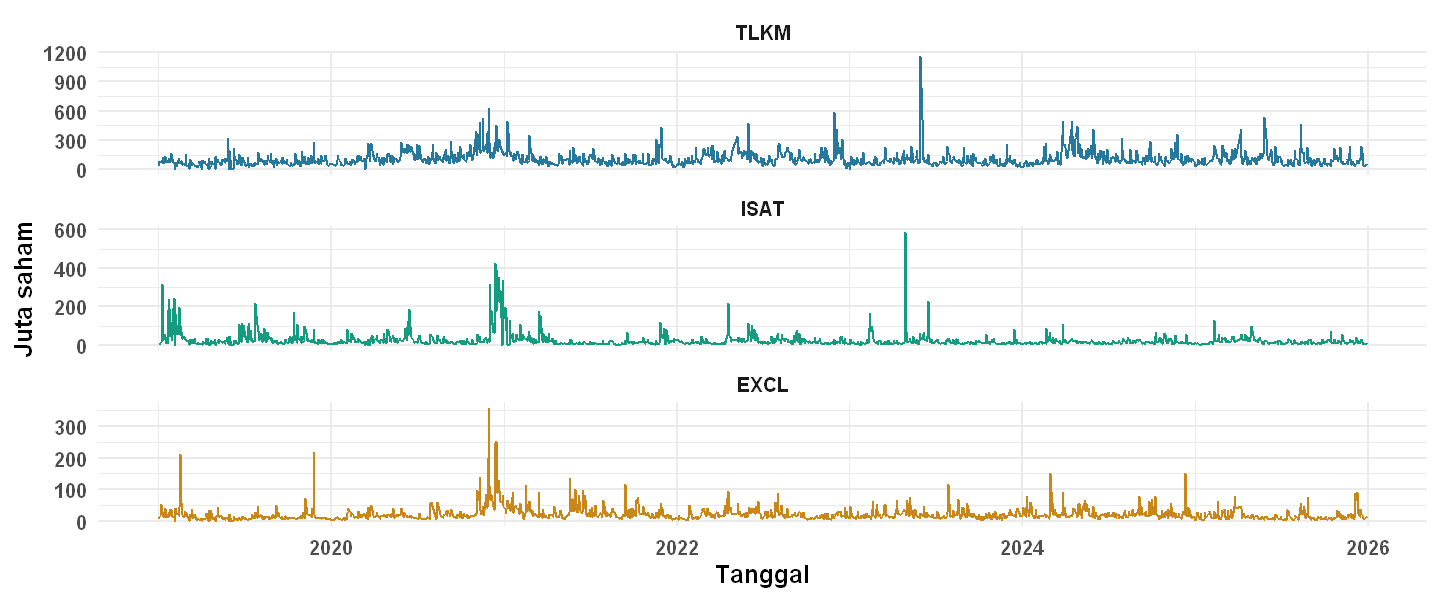

In [6]:
ggplot(long_series(volume), aes(Tanggal, Nilai / 1e6, color = Saham)) +
    geom_line(linewidth = 0.6) +
    facet_wrap(~Saham, ncol = 1, scales = "free_y") +
    scale_color_manual(values = COLORS) +
    labs(x = "Tanggal", y = "Juta saham") +
    theme(legend.position = "none")

## 4. Perhitungan Simple Return
### 4.1. Simple Return Harian

Simple return mengukur perubahan harga dari satu observasi ke observasi berikutnya.

$$r_t=\frac{P_t-P_{t-1}}{P_{t-1}}.$$

$P_t$ adalah harga penutupan yang telah disesuaikan pada waktu $t$. Return positif berarti harga naik.

In [7]:
simple_returns_all <- na.omit(ROC(prices, type = "discrete"))
data.frame(Saham = SAHAM, `Jumlah harga` = nrow(prices),
           `Jumlah simple return sebelum pembersihan` = nrow(simple_returns_all),
           check.names = FALSE)

Saham,Jumlah harga,Jumlah simple return sebelum pembersihan
<chr>,<int>,<int>
TLKM,1704,1703
ISAT,1704,1703
EXCL,1704,1703


### 4.2. Pembersihan Return Nol Serentak

Hari ketika return ketiga saham sama-sama nol dikeluarkan. **25 Agustus 2023** tetap disertakan karena ketiga saham mencatat volume perdagangan. Tabel menunjukkan volume dan status setiap tanggal dengan return nol serentak.

In [8]:
tanggal_return <- as.Date(index(simple_returns_all))
semua_nol <- rowSums(coredata(simple_returns_all) == 0) == ncol(simple_returns_all)
hapus <- HAPUS_HARI_NOL & semua_nol & !(tanggal_return %in% TANGGAL_DIPERTAHANKAN)

tanggal_nol <- tanggal_return[semua_nol]
volume_nol <- coredata(volume[tanggal_nol])
zero_return_check <- data.frame(
    Tanggal = tanggal_nol,
    Volume_TLKM = volume_nol[, "TLKM"],
    Volume_ISAT = volume_nol[, "ISAT"],
    Volume_EXCL = volume_nol[, "EXCL"],
    Status = ifelse(hapus[semua_nol], "Dikeluarkan", "Dipertahankan")
)

simple_returns <- simple_returns_all[!hapus, ]
tabel_return <- data.frame(Tanggal = as.Date(index(simple_returns)), coredata(simple_returns))
cat("Jumlah hari return nol serentak yang dikeluarkan =", sum(hapus), "\n")

zero_return_check
data.frame(Saham = SAHAM, Jumlah_return = nrow(simple_returns))
head(tabel_return, 10)
tail(tabel_return)

Jumlah hari return nol serentak yang dikeluarkan = 12 


Tanggal,Volume_TLKM,Volume_ISAT,Volume_EXCL,Status
<date>,<dbl>,<dbl>,<dbl>,<chr>
2019-02-05,0,0,0,Dikeluarkan
2019-03-07,0,0,0,Dikeluarkan
2019-04-03,0,0,0,Dikeluarkan
2019-04-17,0,0,0,Dikeluarkan
2019-04-19,0,0,0,Dikeluarkan
2019-05-01,0,0,0,Dikeluarkan
2019-05-30,0,0,0,Dikeluarkan
2019-06-03,0,0,0,Dikeluarkan
2019-06-04,0,0,0,Dikeluarkan


Saham,Jumlah_return
<chr>,<int>
TLKM,1691
ISAT,1691
EXCL,1691


,Tanggal,TLKM,ISAT,EXCL
,<date>,<dbl>,<dbl>,<dbl>
1,2019-01-03,0.0026810,0.0030397,0.020202
2,2019-01-04,-0.0080213,0.0454544,0.009901
3,2019-01-07,0.0161724,0.0231885,0.049020
4,2019-01-08,0.0079575,0.0226629,0.023364
5,2019-01-09,-0.0184211,0.2465375,0.027397
6,2019-01-10,0.0187668,-0.1355556,0.000000
7,2019-01-11,0.0157894,0.0154241,-0.022222
8,2019-01-14,-0.0025906,0.0632911,-0.040909
9,2019-01-15,0.0207792,0.0142858,0.037915


,Tanggal,TLKM,ISAT,EXCL
,<date>,<dbl>,<dbl>,<dbl>
1686,2025-12-19,-0.0144508,0.0167365,0.0569106
1687,2025-12-22,0.0175953,0.0041153,-0.0358974
1688,2025-12-23,0.0000000,-0.0081968,-0.0053191
1689,2025-12-24,-0.0028819,-0.0082644,0.0026738
1690,2025-12-29,0.0086706,0.0166667,0.0213333
1691,2025-12-30,-0.0028653,-0.0491804,-0.0208877


### 4.3. Contoh Perhitungan Simple Return

Contoh ini memakai dua harga berurutan dari saham TLKM dan menampilkan hasilnya dalam desimal dan persen.

In [9]:
saham_contoh <- "TLKM"
previous_price <- as.numeric(prices[1, saham_contoh])
current_price <- as.numeric(prices[2, saham_contoh])
example_return <- current_price / previous_price - 1
data.frame(Saham = saham_contoh,
    `Tanggal sebelumnya` = as.Date(index(prices)[1]), Tanggal = as.Date(index(prices)[2]),
    `Harga sebelumnya` = previous_price, `Harga saat ini` = current_price,
    `Simple return` = example_return, `Simple return (%)` = 100 * example_return,
    check.names = FALSE)

Saham,Tanggal sebelumnya,Tanggal,Harga sebelumnya,Harga saat ini,Simple return,Simple return (%)
<chr>,<date>,<date>,<dbl>,<dbl>,<dbl>,<dbl>
TLKM,2019-01-02,2019-01-03,2423.7,2430.2,0.002681,0.2681


### 4.4. Statistik Deskriptif Simple Return

Rata-rata return harian 2019–2024 dipakai sebagai perkiraan *expected return*. Variansi menunjukkan seberapa besar return menyebar di sekitar rata-ratanya.

In [10]:
return_estimasi <- simple_returns[index(simple_returns) <= ESTIMASI_AKHIR]
data_return_estimasi <- long_series(return_estimasi)
return_summary <- data.frame(
    Saham = SAHAM,
    N = nrow(return_estimasi),
    Mean = round(colMeans(return_estimasi), 6),
    Variance = round(apply(return_estimasi, 2, var), 6),
    Min = round(apply(return_estimasi, 2, min), 4),
    Max = round(apply(return_estimasi, 2, max), 4),
    Skewness = round(apply(return_estimasi, 2, moments::skewness), 3),
    Kurtosis = round(apply(return_estimasi, 2, moments::kurtosis), 3),
    Zero_Ret = colSums(return_estimasi == 0),
    check.names = FALSE, row.names = NULL
)
return_summary

Saham,N,Mean,Variance,Min,Max,Skewness,Kurtosis,Zero_Ret
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TLKM,1455,0.000138,0.000338,-0.0696,0.1374,0.616,7.618,121
ISAT,1455,0.001960,0.001214,-0.1356,0.2478,1.722,11.980,115
EXCL,1455,0.000481,0.000687,-0.0925,0.2482,1.203,10.918,153


## 5. Eksplorasi Data Simple Return
### 5.1. Pergerakan Simple Return Harian

Grafik menampilkan perubahan return selama periode estimasi 2019–2024. Bagian 5.6 memakai data 2019–2025.

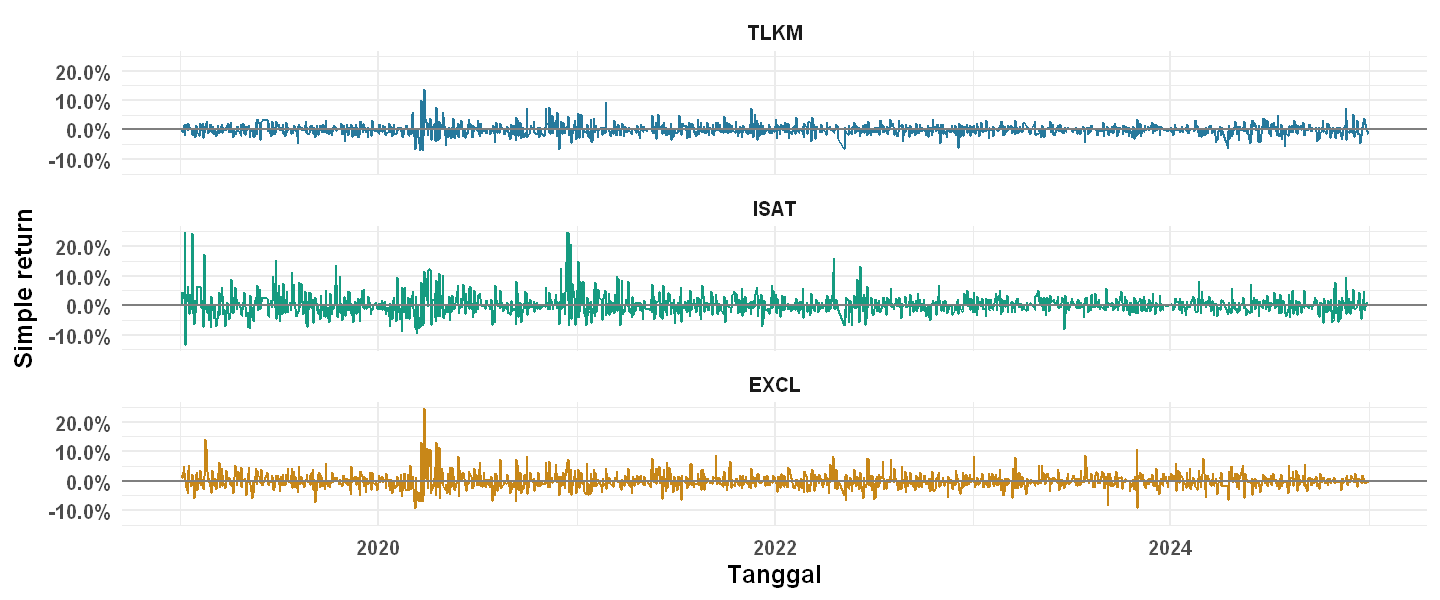

In [11]:
ggplot(data_return_estimasi, aes(Tanggal, Nilai, color = Saham)) +
    geom_line(linewidth = 0.6) + geom_hline(yintercept = 0, color = "grey50", linewidth = 0.8) +
    facet_wrap(~Saham, ncol = 1) + scale_color_manual(values = COLORS) +
    scale_y_continuous(labels = percent) +
    labs(x = "Tanggal", y = "Simple return") + theme(legend.position = "none")

### 5.2. Histogram dan Distribusi Normal Pembanding

Garis putus-putus menunjukkan bentuk distribusi normal sebagai pembanding untuk histogram tiap saham.

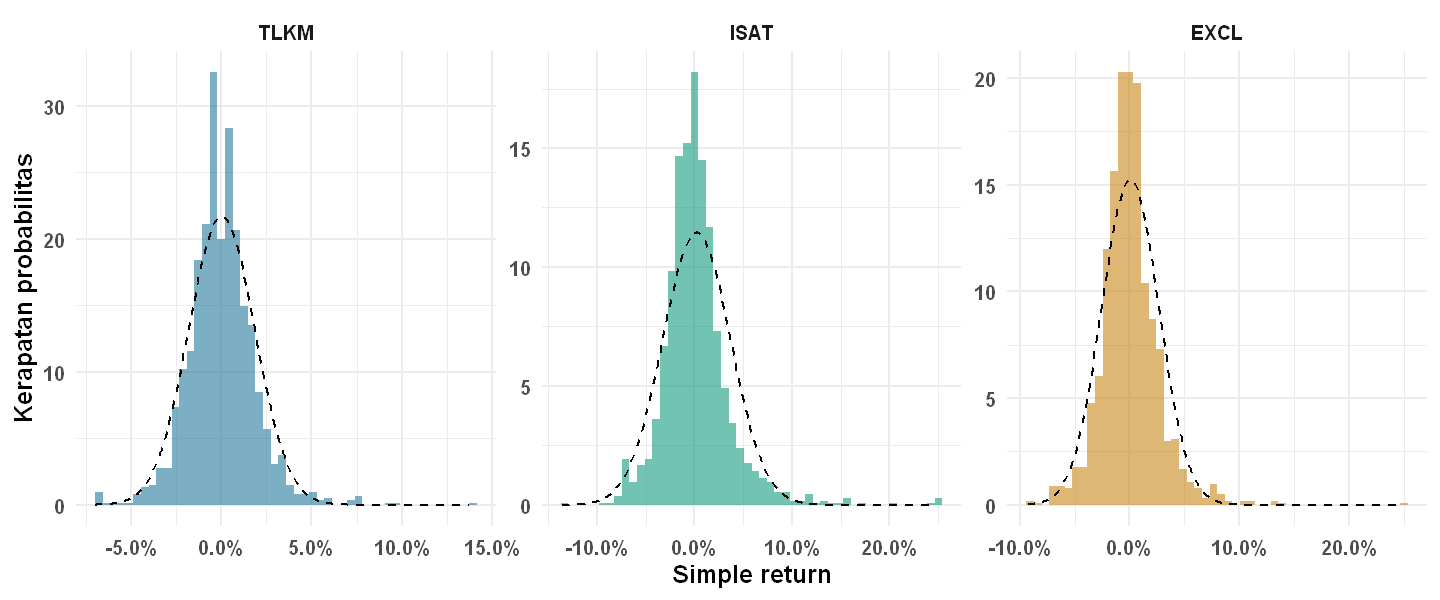

In [12]:
kurva_per_saham <- lapply(SAHAM, function(saham) {
    x <- as.numeric(return_estimasi[, saham])
    grid <- seq(min(x), max(x), length.out = 400)
    data.frame(
        Saham = factor(saham, levels = SAHAM),
        Nilai = grid,
        Densitas = dnorm(grid, mean(x), sd(x))
    )
})
normal_curves <- bind_rows(kurva_per_saham)

ggplot(data_return_estimasi, aes(Nilai)) +
    geom_histogram(aes(y = after_stat(density), fill = Saham), bins = 50, alpha = 0.6) +
    geom_line(data = normal_curves, aes(y = Densitas), linetype = "dashed", linewidth = 0.8) +
    facet_wrap(~Saham, scales = "free") + scale_fill_manual(values = COLORS) +
    scale_x_continuous(labels = percent) +
    labs(x = "Simple return", y = "Kerapatan probabilitas") + theme(legend.position = "none")

### 5.3. Boxplot Simple Return

Boxplot menunjukkan median, penyebaran, dan nilai ekstrem. Nilai ekstrem tetap digunakan untuk mengestimasi risiko kerugian.

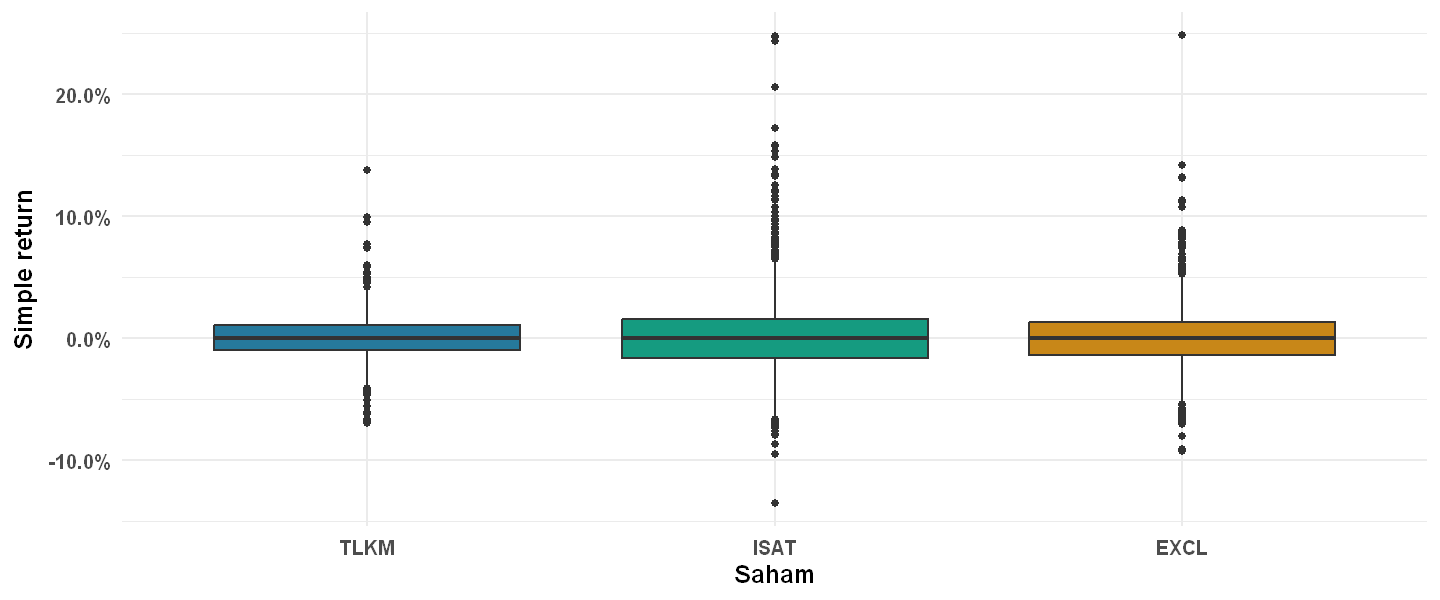

In [13]:
ggplot(data_return_estimasi, aes(Saham, Nilai, fill = Saham)) +
    geom_boxplot(outlier.size = 2, linewidth = 0.7) + scale_fill_manual(values = COLORS) +
    scale_y_continuous(labels = percent) +
    labs(x = "Saham", y = "Simple return") + theme(legend.position = "none")

### 5.4. Q–Q Plot terhadap Distribusi Normal

Titik yang menjauh dari garis menunjukkan bagian distribusi return yang berbeda dari pola normal.

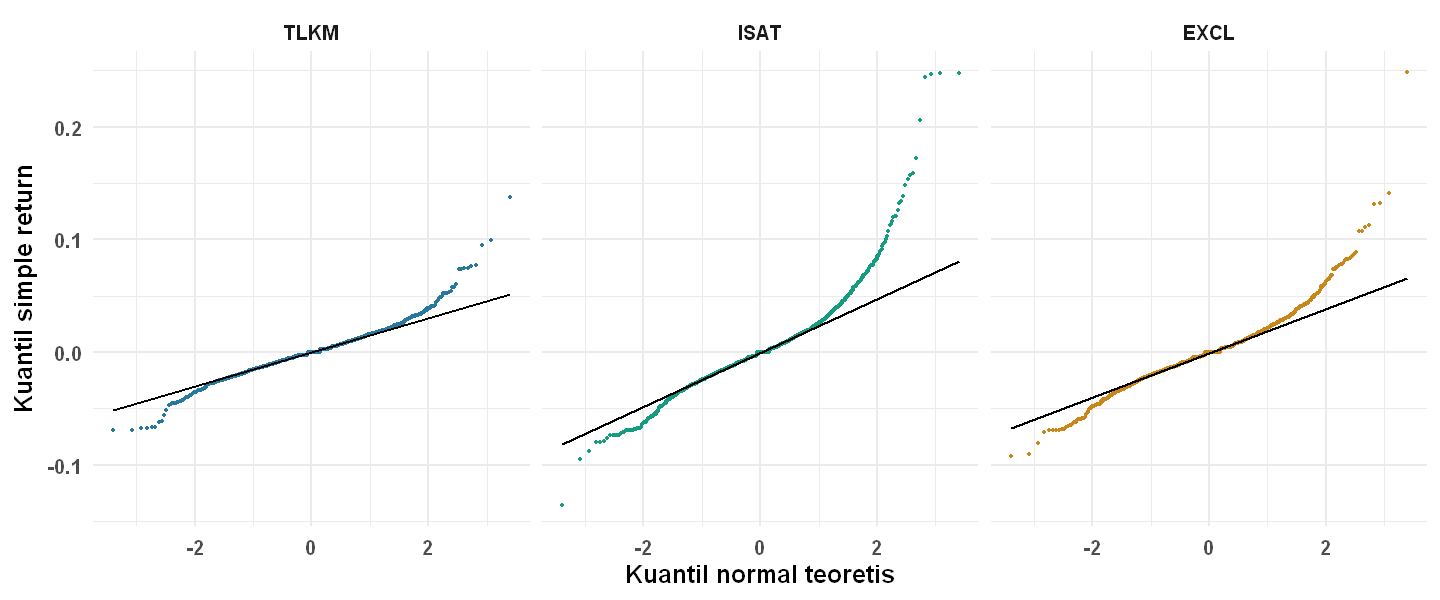

In [14]:
ggplot(data_return_estimasi, aes(sample = Nilai, color = Saham)) +
    stat_qq(size = 0.8) + stat_qq_line(color = "black", linewidth = 0.8) +
    facet_wrap(~Saham) + scale_color_manual(values = COLORS) +
    labs(x = "Kuantil normal teoretis", y = "Kuantil simple return") +
    theme(legend.position = "none")

### 5.5. Uji Normalitas Return

Uji Jarque–Bera (JB) dan Kolmogorov–Smirnov (KS) digunakan untuk memeriksa normalitas return 2019–2024. Keputusan pada tabel mengikuti uji JB dengan taraf signifikansi 5%.

In [15]:
normalitas_per_saham <- lapply(SAHAM, function(saham) {
    r <- as.numeric(return_estimasi[, saham])
    jb_p <- moments::jarque.test(r)$p.value
    ks_p <- suppressWarnings(ks.test(r, "pnorm", mean(r), sd(r)))$p.value
    data.frame(
        Saham = saham,
        JB_pvalue = format.pval(jb_p, digits = 3),
        KS_pvalue = format.pval(ks_p, digits = 3),
        Normalitas = ifelse(jb_p < SIGNIFICANCE, "Tolak H0 (tidak normal)", "Gagal menolak H0")
    )
})
norm_tab <- bind_rows(normalitas_per_saham)
norm_tab

Saham,JB_pvalue,KS_pvalue,Normalitas
<chr>,<chr>,<chr>,<chr>
TLKM,<2e-16,6.25e-05,Tolak H0 (tidak normal)
ISAT,<2e-16,4.93e-14,Tolak H0 (tidak normal)
EXCL,<2e-16,9.79e-10,Tolak H0 (tidak normal)


### 5.6. Statistik Simple Return per Tahun

Tabel membandingkan rata-rata dan penyebaran return harian dari tahun ke tahun.

In [16]:
return_tahunan <- mutate(long_series(simple_returns), Tahun = as.integer(format(Tanggal, "%Y")))
kelompok_tahunan <- group_by(return_tahunan, Tahun, Saham)
annual_summary <- summarise(
    kelompok_tahunan, N = n(), Mean = mean(Nilai), Variansi = var(Nilai), Std = sd(Nilai),
    Minimum = min(Nilai), Maksimum = max(Nilai), .groups = "drop"
)
annual_summary

Tahun,Saham,N,Mean,Variansi,Std,Minimum,Maksimum
<int>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2019,TLKM,244,5.3453e-04,0.00021756,0.014750,-0.046729,0.035897
2019,ISAT,244,3.3707e-03,0.00216699,0.046551,-0.135556,0.246537
2019,EXCL,244,2.2130e-03,0.00062732,0.025046,-0.071023,0.141463
2020,TLKM,242,-1.9771e-04,0.00070970,0.026640,-0.069620,0.137404
2020,ISAT,242,3.3838e-03,0.00233286,0.048300,-0.094987,0.247788
2020,EXCL,242,1.5661e-04,0.00149122,0.038616,-0.090909,0.248227
2021,TLKM,247,1.1744e-03,0.00034214,0.018497,-0.041420,0.094637
2021,ISAT,247,1.7852e-03,0.00105566,0.032491,-0.069536,0.148515
2021,EXCL,247,9.1900e-04,0.00050910,0.022563,-0.065134,0.088561


## 6. Metode Estimasi Value at Risk
### 6.1. VaR dan Block Maxima

VaR memperkirakan ambang kerugian pada tingkat kepercayaan tertentu. VaR harian 95% sebesar 3% berarti model memperkirakan kerugian melebihi 3% pada sekitar 5% hari perdagangan.

Kerugian dihitung sebagai negatif return ($L_t=-r_t$). Metode Block Maxima mengambil kerugian terbesar dari setiap blok lima observasi berurutan. Blok tidak saling tumpang tindih. Blok terakhir dikeluarkan jika observasinya kurang dari lima.

### 6.2. Distribusi GEV dan VaR Harian

Distribusi GEV dipasang pada maksimum kerugian tiap blok dengan metode kemungkinan maksimum. Jika kerugian harian diasumsikan independen dan mengikuti distribusi yang sama, VaR harian pada tingkat kepercayaan $c$ dihitung dari kuantil GEV pada peluang $c^m$.

$$q_c=G_m^{-1}(c^m), \qquad m=5.$$

### 6.3. VaR dalam Persen dan Rupiah

VaR desimal dikalikan 100 agar terbaca dalam persen, atau dikalikan Rp1 miliar untuk memperoleh nilai kerugian dalam rupiah per saham.

In [17]:
block_maxima <- function(loss, m) {
    n_lengkap <- length(loss) %/% m * m
    blok <- matrix(head(loss, n_lengkap), nrow = m)
    apply(blok, 2, max)
}

fit_gev <- function(bm) {
    tryCatch(
        evd::fgev(bm, std.err = TRUE),
        error = function(e) evd::fgev(bm, std.err = FALSE)
    )
}

var_gev <- function(par, m, level) {
    evd::qgev(level^m, loc = par[["loc"]], scale = par[["scale"]], shape = par[["shape"]])
}

## 7. Estimasi Value at Risk
### 7.1. Periode Estimasi dan Periode Backtesting

Model memakai return 2019–2024. VaR hasil estimasi digunakan sebagai ambang tetap sepanjang periode backtesting tahun 2025.

In [18]:
tanggal <- index(simple_returns)
return_backtesting <- simple_returns[tanggal >= BACKTESTING_AWAL & tanggal <= BACKTESTING_AKHIR]
kerugian_estimasi <- -return_estimasi
kerugian_backtesting <- -return_backtesting
split_summary <- data.frame(
    Periode = c("Estimasi", "Backtesting"),
    `Awal return` = as.Date(c(index(return_estimasi)[1], index(return_backtesting)[1])),
    `Akhir return` = as.Date(c(tail(index(return_estimasi), 1), tail(index(return_backtesting), 1))),
    `N return per saham` = c(nrow(return_estimasi), nrow(return_backtesting)), check.names = FALSE
)
split_summary

Periode,Awal return,Akhir return,N return per saham
<chr>,<date>,<date>,<int>
Estimasi,2019-01-03,2024-12-30,1455
Backtesting,2025-01-02,2025-12-30,236


### 7.2. Estimasi GEV dan Uji Gumbel

Model GEV memiliki parameter lokasi, skala, dan bentuk. Uji rasio kemungkinan membandingkannya dengan model Gumbel, yang menetapkan parameter bentuk $\xi=0$.

In [19]:
fits <- setNames(lapply(SAHAM, function(saham) {
    kerugian <- as.numeric(kerugian_estimasi[, saham])
    bm <- block_maxima(kerugian, BLOCK_SIZE)
    list(bm = bm, fit = fit_gev(bm))
}), SAHAM)

parameter_per_saham <- lapply(SAHAM, function(saham) {
    bm <- fits[[saham]]$bm
    gev <- fits[[saham]]$fit
    parameter <- gev$estimate
    shape <- parameter[["shape"]]
    se_shape <- gev$std.err[["shape"]]
    if (is.null(se_shape)) se_shape <- NA_real_
    ci_shape <- shape + c(-1, 1) * 1.96 * se_shape

    tipe_ekor <- if (isTRUE(ci_shape[1] > 0)) {
        "Heavy tail (Frechet)"
    } else if (isTRUE(ci_shape[2] < 0)) {
        "Ekor pendek (Weibull)"
    } else {
        "xi tidak signifikan beda dari 0"
    }

    gumbel <- tryCatch(
        evd::fgev(bm, shape = 0, std.err = FALSE),
        error = function(e) NULL
    )
    p_gumbel <- if (is.null(gumbel)) NA_real_ else {
        1 - pchisq(gumbel$deviance - gev$deviance, df = 1)
    }

    data.frame(
        Saham = saham, Jml_Blok = length(bm),
        Location = round(parameter[["loc"]], 5),
        Scale = round(parameter[["scale"]], 5),
        Shape = round(shape, 4),
        Shape_CI95 = sprintf("[%.3f ; %.3f]", ci_shape[1], ci_shape[2]),
        LR_Gumbel_p = round(p_gumbel, 4),
        Tipe_Ekor = tipe_ekor,
        Konvergensi = gev$convergence
    )
})
parameter_GEV <- bind_rows(parameter_per_saham)
parameter_GEV

Saham,Jml_Blok,Location,Scale,Shape,Shape_CI95,LR_Gumbel_p,Tipe_Ekor,Konvergensi
<chr>,<int>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<chr>
TLKM,291,0.01370,0.00994,-0.0121,[-0.075 ; 0.051],0.8131,xi tidak signifikan beda dari 0,successful
ISAT,291,0.02088,0.01610,-0.0204,[-0.089 ; 0.048],0.5687,xi tidak signifikan beda dari 0,successful
EXCL,291,0.01813,0.01332,-0.0119,[-0.090 ; 0.066],0.7829,xi tidak signifikan beda dari 0,successful


### 7.3. Histogram dan Distribusi GEV

Batang menunjukkan sebaran kerugian maksimum per blok. Garis putus-putus menunjukkan distribusi GEV yang dipakai untuk menghitung VaR.

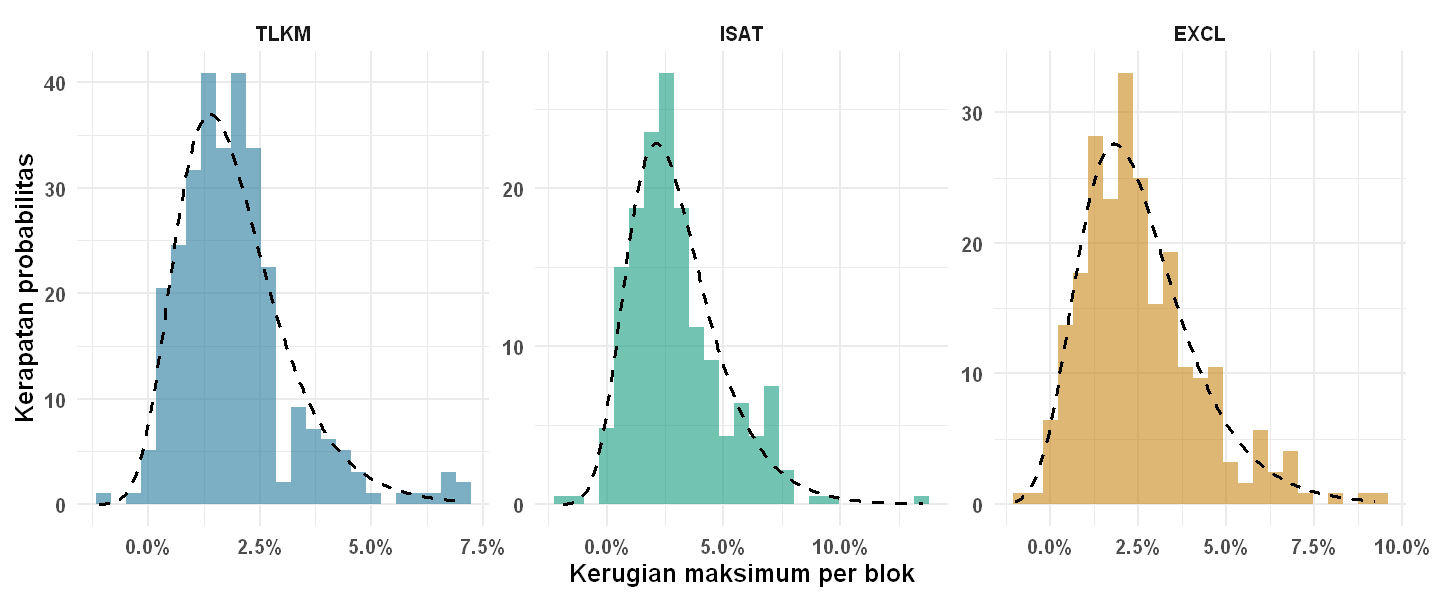

In [20]:
maksimum_blok <- bind_rows(lapply(SAHAM, function(saham) {
    data.frame(Saham = saham, Kerugian = fits[[saham]]$bm)
}))
kurva_gev <- bind_rows(lapply(SAHAM, function(saham) {
    bm <- fits[[saham]]$bm
    par <- fits[[saham]]$fit$estimate
    x <- seq(min(bm), max(bm), length.out = 400)
    densitas <- evd::dgev(x, loc = par[["loc"]], scale = par[["scale"]], shape = par[["shape"]])
    data.frame(Saham = saham, Kerugian = x, Densitas = densitas)
}))
maksimum_blok$Saham <- factor(maksimum_blok$Saham, levels = SAHAM)
kurva_gev$Saham <- factor(kurva_gev$Saham, levels = SAHAM)

ggplot(maksimum_blok, aes(Kerugian)) +
    geom_histogram(aes(y = after_stat(density), fill = Saham), bins = 25, alpha = 0.6) +
    geom_line(data = kurva_gev, aes(y = Densitas), linetype = "dashed", linewidth = 1) +
    facet_wrap(~Saham, scales = "free") +
    scale_fill_manual(values = COLORS) +
    scale_x_continuous(labels = percent) +
    labs(x = "Kerugian maksimum per blok", y = "Kerapatan probabilitas") +
    theme(legend.position = "none", plot.margin = margin(8, 20, 8, 8))

### 7.4. Grafik Kesesuaian GEV

Grafik membantu melihat seberapa dekat distribusi GEV dengan data maksimum kerugian.

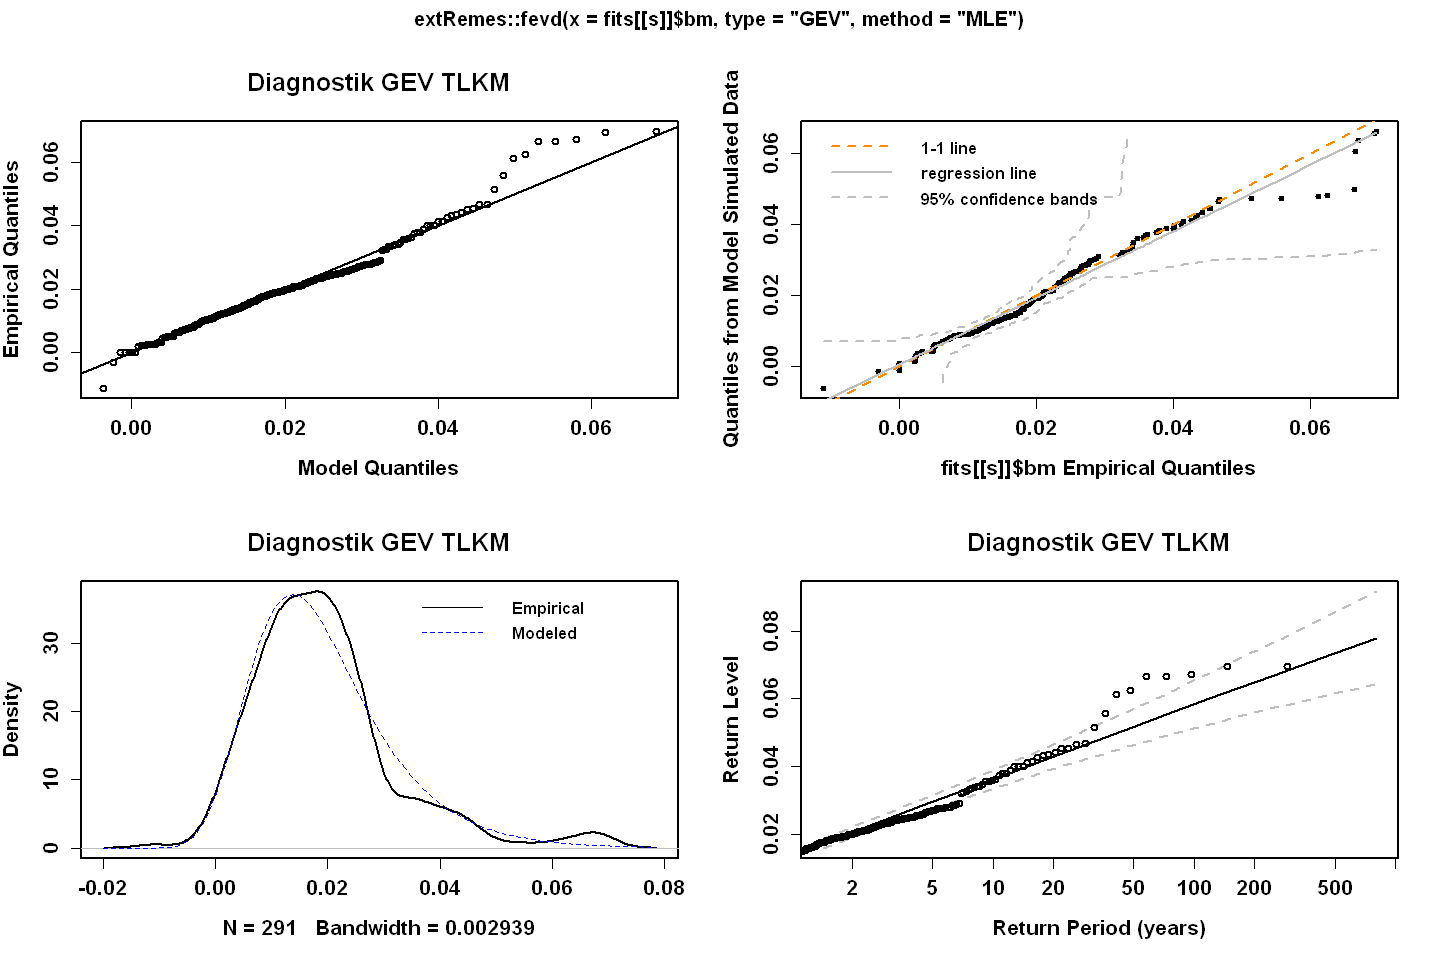

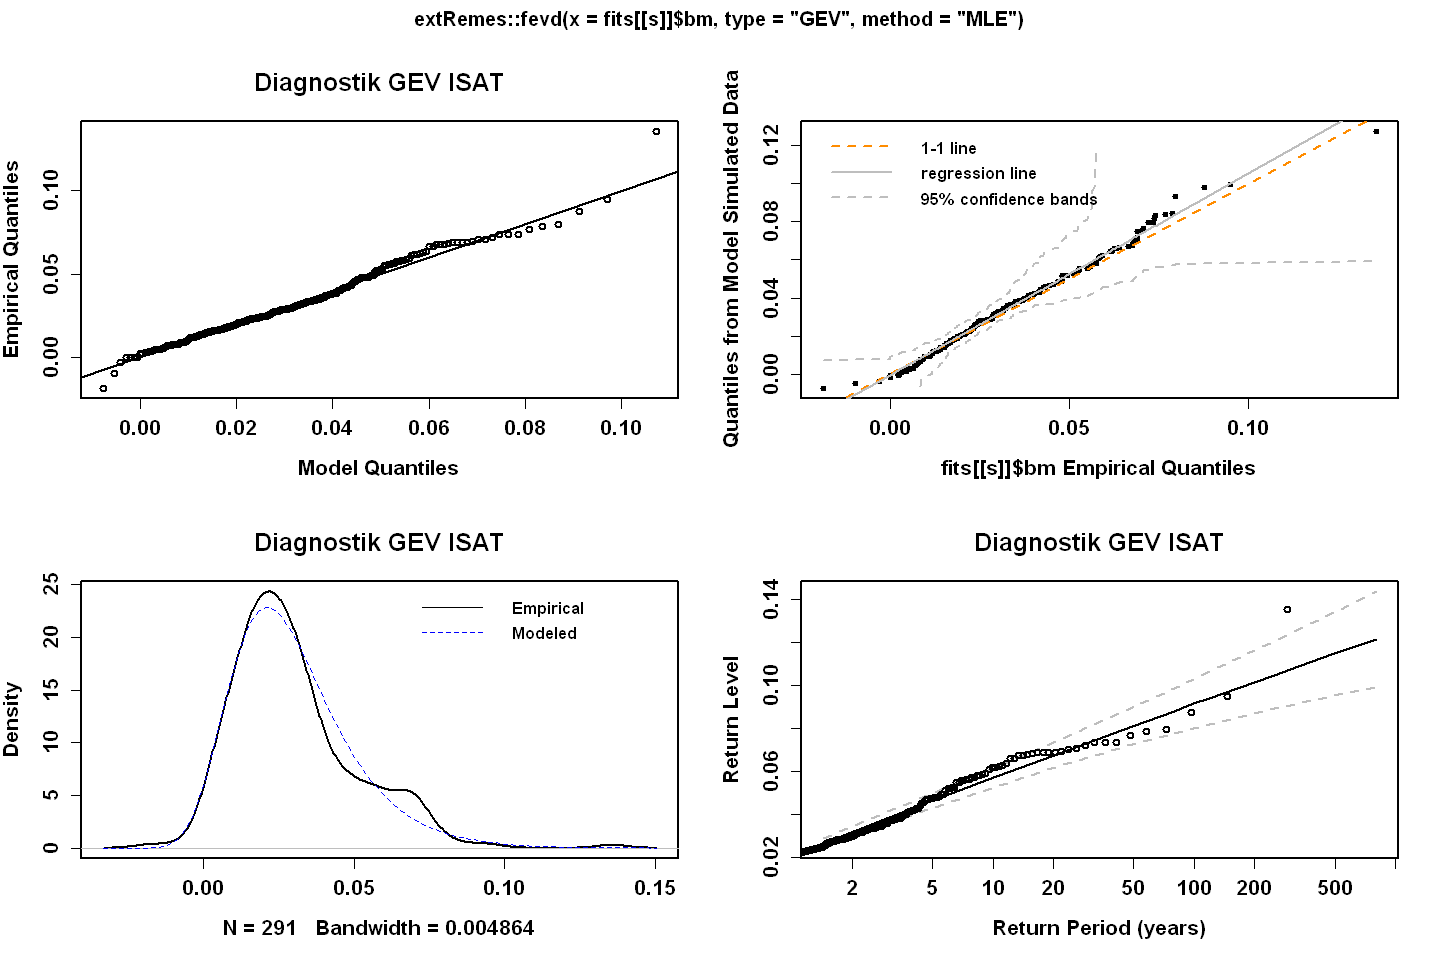

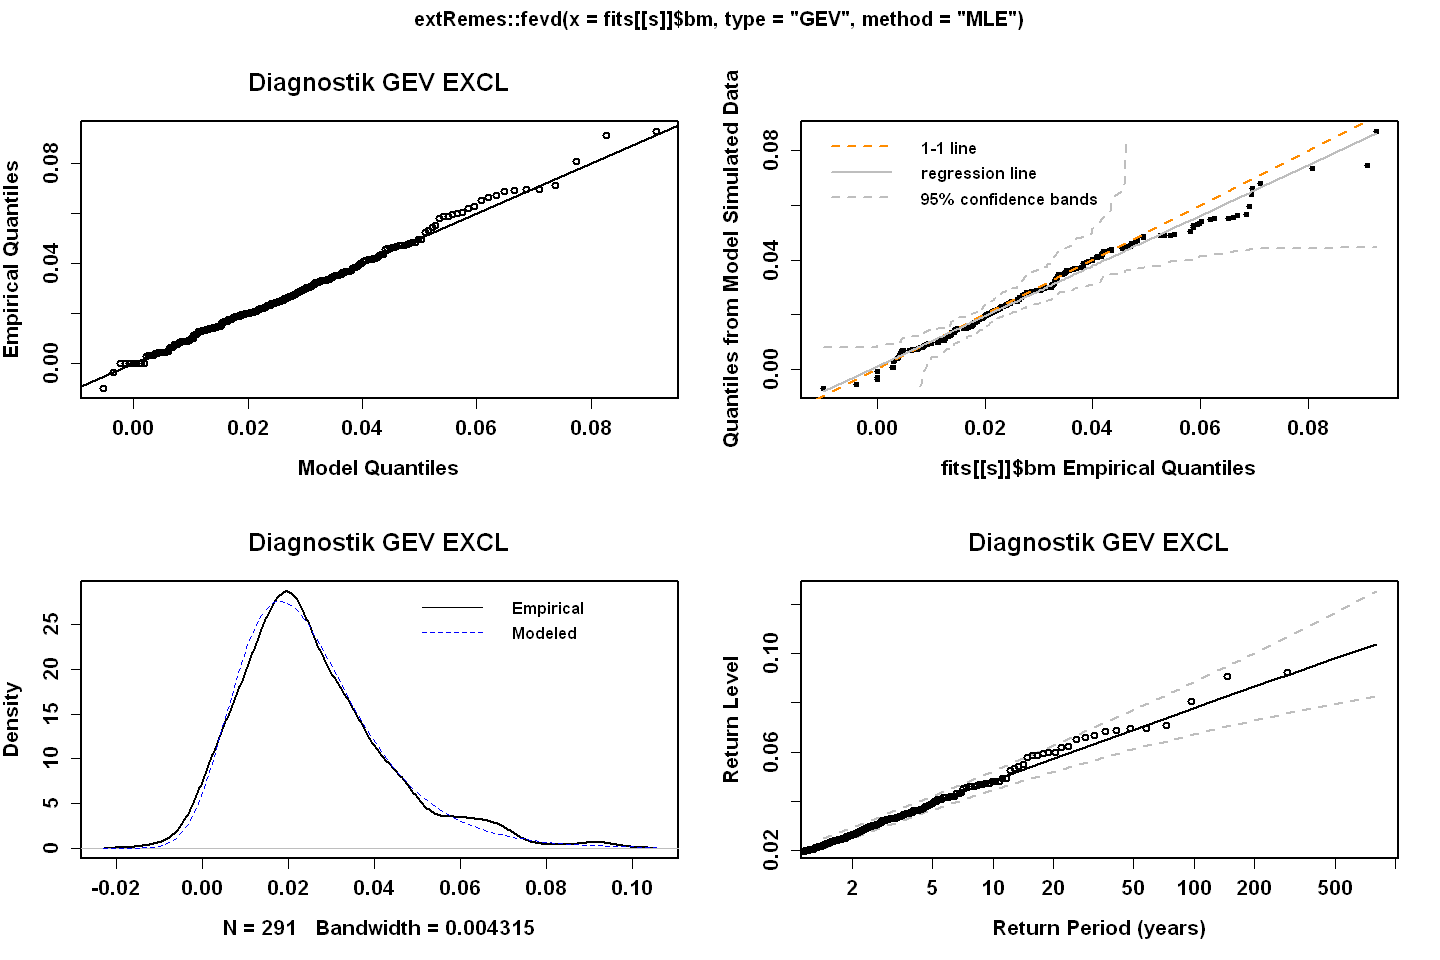

In [21]:
options(repr.plot.bg = "white", repr.plot.height = 8)

for (s in SAHAM) {
    par(
        bg = "white", font = 2, font.axis = 2, font.lab = 2, font.main = 2, font.sub = 2,
        cex.axis = 15 / 12, cex.lab = 15 / 12, cex.main = 1.2 * 15 / 12, lwd = 1.6
    )
    diagnostic_fit <- extRemes::fevd(fits[[s]]$bm, type = "GEV", method = "MLE")
    plot(diagnostic_fit, main = paste("Diagnostik GEV", s))
}

### 7.5. Uji Kesesuaian GEV dengan Kolmogorov–Smirnov

Uji KS membandingkan distribusi maksimum kerugian dalam data dengan distribusi GEV hasil estimasi. Hasil uji dibaca bersama grafik kesesuaian.

In [22]:
kesesuaian_per_saham <- lapply(SAHAM, function(saham) {
    bm <- fits[[saham]]$bm
    par <- fits[[saham]]$fit$estimate
    ks_gev <- suppressWarnings(
        ks.test(bm, evd::pgev, loc = par[["loc"]], scale = par[["scale"]], shape = par[["shape"]])
    )
    data.frame(
        Saham = saham,
        D_KS = round(as.numeric(ks_gev$statistic), 4),
        P_Value = round(ks_gev$p.value, 4),
        Keputusan = ifelse(ks_gev$p.value > SIGNIFICANCE, "Gagal menolak H0", "Tolak H0")
    )
})
gof_GEV <- bind_rows(kesesuaian_per_saham)
gof_GEV

Saham,D_KS,P_Value,Keputusan
<chr>,<dbl>,<dbl>,<chr>
TLKM,0.0614,0.2229,Gagal menolak H0
ISAT,0.0426,0.6673,Gagal menolak H0
EXCL,0.0311,0.9412,Gagal menolak H0


### 7.6. VaR Harian pada Tingkat Kepercayaan 95% dan 99%

Tabel membandingkan ambang kerugian harian tiap saham dalam persen dan rupiah.

In [23]:
var_per_saham <- lapply(SAHAM, function(saham) {
    par <- fits[[saham]]$fit$estimate
    data.frame(
        Saham = saham,
        Level = CONFIDENCE_LEVELS,
        VaR = var_gev(par, BLOCK_SIZE, CONFIDENCE_LEVELS)
    )
})
nilai_var <- bind_rows(var_per_saham)

VaR_BM <- transmute(
    nilai_var, Saham, Level,
    VaR_BM = round(VaR, 5),
    Persentase_Risiko = paste0(round(VaR * 100, 2), "%"),
    Estimasi_Rugi_Rp = format(
        round(VaR * INVESTMENT), big.mark = ".", decimal.mark = ",",
        scientific = FALSE, trim = TRUE
    )
)
VaR_BM

Saham,Level,VaR_BM,Persentase_Risiko,Estimasi_Rugi_Rp
<chr>,<dbl>,<dbl>,<chr>,<chr>
TLKM,0.95,0.02712,2.71%,27.120.619
TLKM,0.99,0.04290,4.29%,42.903.163
ISAT,0.95,0.04249,4.25%,42.486.165
ISAT,0.99,0.06760,6.76%,67.595.778
EXCL,0.95,0.03611,3.61%,36.110.781
EXCL,0.99,0.05726,5.73%,57.264.318


## 8. Backtesting dengan Uji Kupiec dan Christoffersen
### 8.1. Pemeriksaan Exception VaR

*Exception* terjadi saat kerugian aktual lebih besar dari VaR. Uji Kupiec memeriksa apakah jumlah *exception* sesuai dengan tingkat kepercayaan. Uji Christoffersen memeriksa apakah *exception* cenderung berurutan. Uji gabungan atau *conditional coverage* mempertimbangkan keduanya. Taraf signifikansi yang digunakan adalah 5%.

Ketiga uji dihitung dengan paket R `tstests`. Tabel menampilkan NA jika paket tidak bisa menghitung uji karena urutan data hanya memuat satu jenis kejadian.

In [24]:
backtest_2025 <- data.frame()
backtest_daily <- data.frame()
tanggal_backtesting <- as.Date(index(kerugian_backtesting))
jumlah_hari <- length(tanggal_backtesting)

for (i in seq_len(nrow(nilai_var))) {
    saham <- nilai_var$Saham[i]
    level <- nilai_var$Level[i]
    ambang_var <- nilai_var$VaR[i]
    kerugian <- as.numeric(kerugian_backtesting[, saham])
    exception <- as.integer(kerugian > ambang_var)
    alpha <- 1 - level

    statistik <- p_value <- rep(NA_real_, 3)
    if (length(unique(head(exception, -1))) == 2 &&
        length(unique(tail(exception, -1))) == 2) {
        hasil <- withCallingHandlers(
            tstests::var_cp_test(
                actual = -kerugian,
                forecast = rep(-ambang_var, jumlah_hari),
                alpha = alpha
            ),
            warning = function(w) {
                if (grepl("unable to calculate duration test CP (D)", conditionMessage(w), fixed = TRUE)) {
                    invokeRestart("muffleWarning")
                }
            }
        )
        statistik <- hasil$table$Statistic[1:3]
        p_value <- hasil$p_value[1:3]
    }

    backtest_2025 <- rbind(backtest_2025, data.frame(
        Saham = saham, Level = level, N_backtesting = jumlah_hari,
        Exception = sum(exception), Expected = round(jumlah_hari * alpha, 1),
        Exception_Rate = round(mean(exception), 4),
        Kupiec_LR = round(statistik[1], 3), Kupiec_p = round(p_value[1], 4),
        Christ_LR = round(statistik[2], 3), Christ_p = round(p_value[2], 4),
        CC_LR = round(statistik[3], 3), CC_p = round(p_value[3], 4),
        Kesimpulan = ifelse(p_value[3] > SIGNIFICANCE, "Valid", "Tidak valid")
    ))
    backtest_daily <- rbind(backtest_daily, data.frame(
        Tanggal = tanggal_backtesting, Saham = saham,
        Kepercayaan = level, Kerugian = kerugian,
        VaR_harian = ambang_var, Exception = exception
    ))
}
backtest_2025

Saham,Level,N_backtesting,Exception,Expected,Exception_Rate,Kupiec_LR,Kupiec_p,Christ_LR,Christ_p,CC_LR,CC_p,Kesimpulan
<chr>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
TLKM,0.95,236,18,11.8,0.0763,2.975,0.0846,0.133,0.7154,3.108,0.2114,Valid
TLKM,0.99,236,6,2.4,0.0254,3.974,0.0462,2.320,0.1277,6.294,0.0430,Tidak valid
ISAT,0.95,236,16,11.8,0.0678,1.423,0.2329,0.871,0.3506,2.294,0.3176,Valid
ISAT,0.99,236,4,2.4,0.0169,0.953,0.3291,3.995,0.0456,4.948,0.0842,Valid
EXCL,0.95,236,5,11.8,0.0212,5.218,0.0224,0.217,0.6410,5.435,0.0660,Valid
EXCL,0.99,236,1,2.4,0.0042,1.011,0.3148,0.009,0.9263,1.019,0.6008,Valid


### 8.2. Grafik Exception VaR Tahun 2025

Garis putus-putus menunjukkan ambang VaR. Titik merah menandai hari ketika kerugian aktual melampaui ambang tersebut.

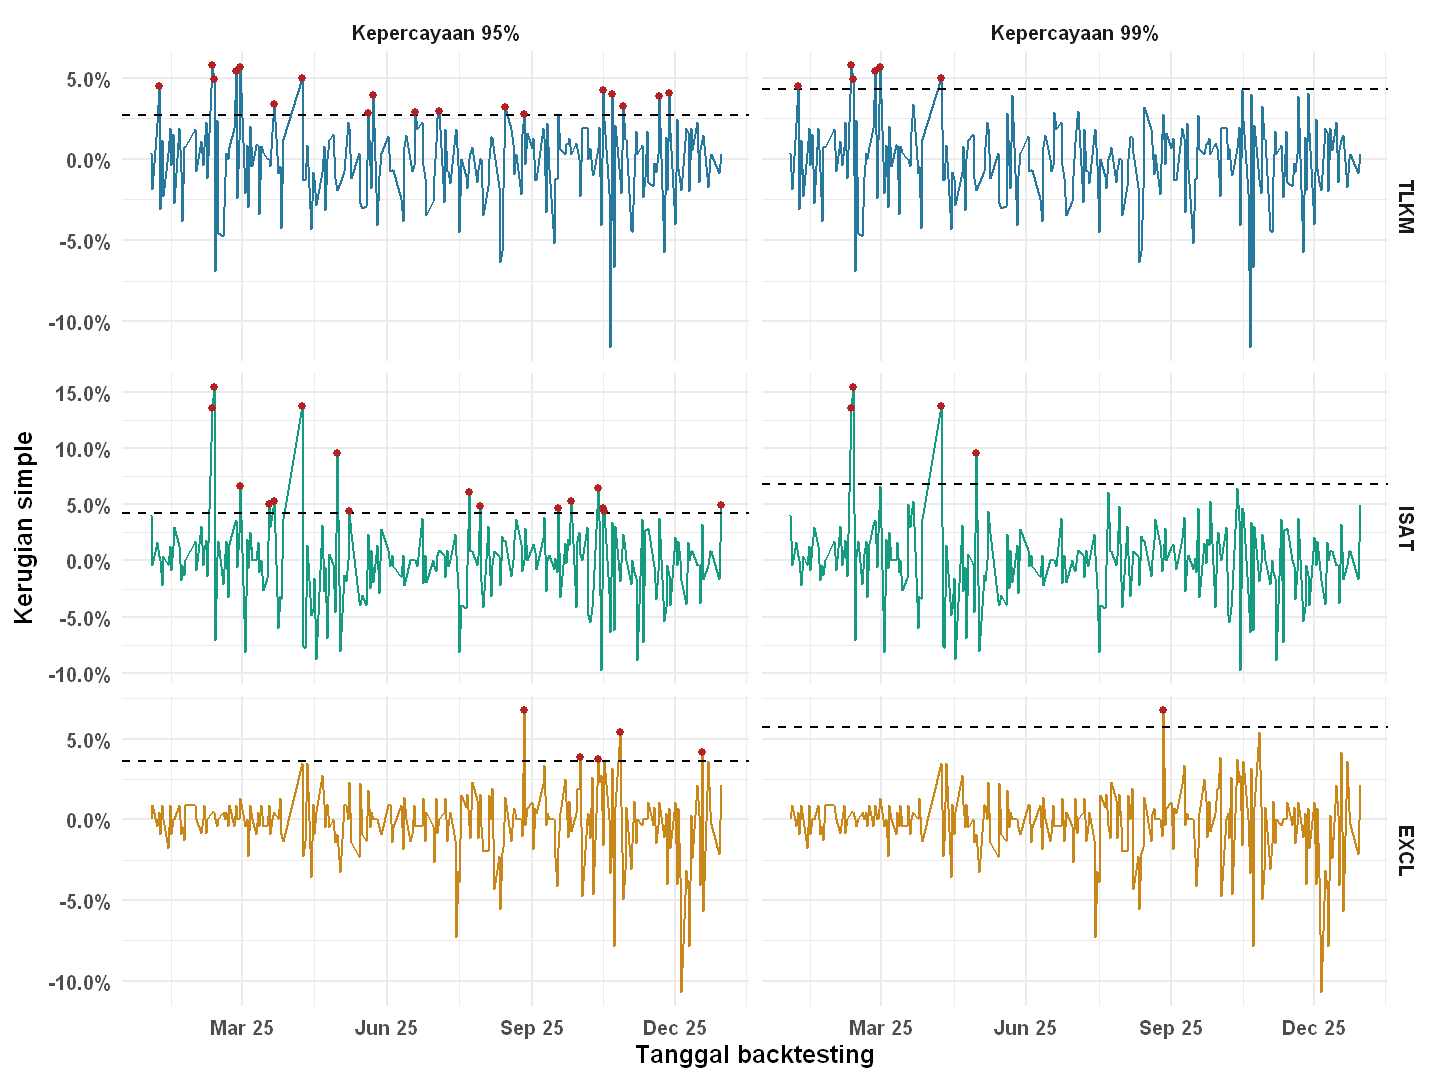

In [25]:
options(repr.plot.height = 9)

plot_daily <- mutate(
    backtest_daily,
    Saham = factor(Saham, levels = SAHAM),
    Tingkat = paste0("Kepercayaan ", 100 * Kepercayaan, "%")
)
thresholds <- distinct(plot_daily, Saham, Tingkat, VaR_harian)
ggplot(plot_daily, aes(Tanggal, Kerugian, color = Saham)) +
    geom_line(linewidth = 0.65) +
    geom_hline(data = thresholds, aes(yintercept = VaR_harian),
               color = "black", linetype = "dashed", linewidth = 0.8) +
    geom_point(data = filter(plot_daily, Exception == 1), color = "firebrick", size = 2) +
    facet_grid(Saham ~ Tingkat, scales = "free_y") + scale_color_manual(values = COLORS) +
    scale_y_continuous(labels = percent) +
    scale_x_date(date_breaks = "3 months", date_labels = "%b %y") +
    labs(x = "Tanggal backtesting", y = "Kerugian simple") + theme(legend.position = "none")